In [127]:
# required imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency

In [128]:
# read in the species_info.csv and observations.csv files as species_info_df and observations_df, respectively
species_info_df = pd.read_csv('species_info.csv')
observations_df = pd.read_csv('observations.csv')


In [129]:
# print the head of the species_info_df dataframe
species_info_df.head()

,category,scientific_name,common_names,conservation_status
0,Mammal,Clethrionomys gapperi gapperi,Gapper's Red-Backed Vole,NaN
1,Mammal,Bos bison,"American Bison, Bison",NaN
2,Mammal,Bos taurus,"Aurochs, Aurochs, Domestic Cattle (Feral), Dom...",NaN
3,Mammal,Ovis aries,"Domestic Sheep, Mouflon, Red Sheep, Sheep (Feral)",NaN
4,Mammal,Cervus elaphus,Wapiti Or Elk,NaN


In [130]:
# print the head of the observations_df dataframe
observations_df.head()

,scientific_name,park_name,observations
0,Vicia benghalensis,Great Smoky Mountains National Park,68
1,Neovison vison,Great Smoky Mountains National Park,77
2,Prunus subcordata,Yosemite National Park,138
3,Abutilon theophrasti,Bryce National Park,84
4,Githopsis specularioides,Great Smoky Mountains National Park,85


In [131]:
# print missing values in observations_df
observations_df.isnull().sum()

scientific_name    0
park_name          0
observations       0
dtype: int64

In [132]:
# get the sum of null values in the species_info_df dataframe
species_info_df.isnull().sum()

category                  0
scientific_name           0
common_names              0
conservation_status    5633
dtype: int64

In [133]:
# show conservation status counts per category
species_info_df['conservation_status'].value_counts(dropna=False)

conservation_status
NaN                   5633
Species of Concern     161
Endangered              16
Threatened              10
In Recovery              4
Name: count, dtype: int64

In [134]:
# check how many conservation statuses are missing in the species_info_ddf dataframe per category
species_info_df.groupby('category')['conservation_status'].apply(lambda x: x.isnull().sum())

category
Amphibian              73
Bird                  442
Fish                  116
Mammal                176
Nonvascular Plant     328
Reptile                74
Vascular Plant       4424
Name: conservation_status, dtype: int64

C:\Users\aidan\AppData\Local\Temp\ipykernel_6152\3626003845.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_percentage.values, y=missing_percentage.index, palette='viridis')


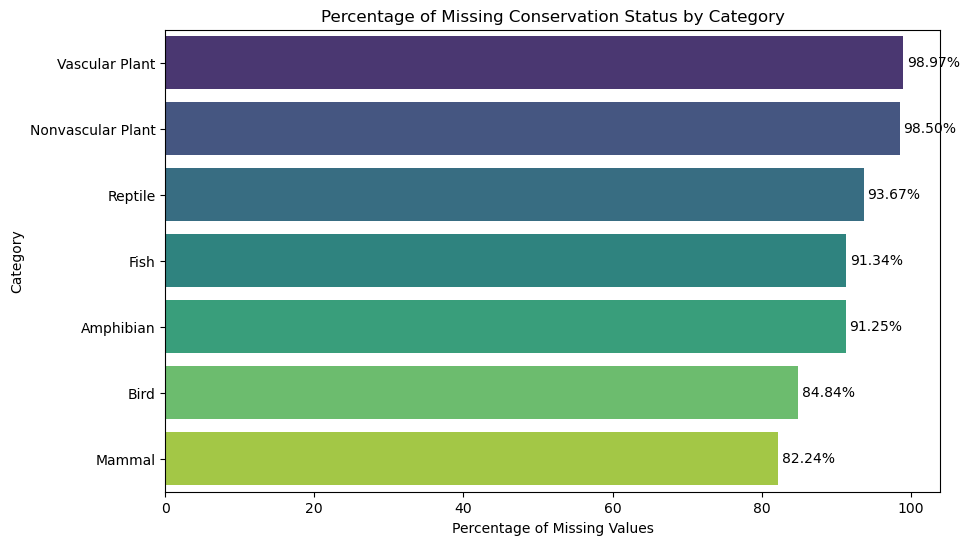

In [135]:
# get missing percentage of conbservation status per category
missing_percentage = species_info_df.groupby('category')['conservation_status'].apply(lambda x: x.isnull().mean() * 100).sort_values(ascending=False)

# visualize the missing percentage of conservation status per category
plt.figure(figsize=(10, 6))
sns.barplot(x=missing_percentage.values, y=missing_percentage.index, palette='viridis')

# add percentage labels to the bars
for index, value in enumerate(missing_percentage.values):
    plt.text(value + 0.5, index, f'{value:.2f}%', va='center')
plt.title('Percentage of Missing Conservation Status by Category')
plt.xlabel('Percentage of Missing Values')
plt.ylabel('Category')
plt.show()
plt.close()

In [136]:
# get sum of duplicate values in species_info_df
species_info_df.duplicated().sum()

np.int64(0)

In [137]:
# get sum of duplicate values in observations_df
observations_df.duplicated().sum()

np.int64(15)

In [138]:
# display all occurrences of the duplicated rows in the observations_df dataframe
observations_df[observations_df.duplicated(keep=False)]

,scientific_name,park_name,observations
365,Plantago major,Great Smoky Mountains National Park,90
513,Arctium minus,Yosemite National Park,162
627,Spilogale putorius,Yellowstone National Park,256
1020,Eleocharis palustris,Great Smoky Mountains National Park,62
1032,Hesperis matronalis,Bryce National Park,124
1454,Echinochloa crus-galli,Great Smoky Mountains National Park,62
1635,Streptopelia decaocto,Yellowstone National Park,255
4178,Monotropa hypopithys,Great Smoky Mountains National Park,73
4527,Botrychium virginianum,Yellowstone National Park,232
7219,Prunella vulgaris,Great Smoky Mountains National Park,75


In [139]:
# remove the duplicated rows from the observations_df dataframe
observations_df = observations_df.drop_duplicates()

In [140]:
# verify that the duplicated rows have been removed by checking the sum of duplicate values in observations_df again
observations_df.duplicated().sum()

np.int64(0)

In [141]:
# species dataset information
species_info_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5824 entries, 0 to 5823
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   category             5824 non-null   object
 1   scientific_name      5824 non-null   object
 2   common_names         5824 non-null   object
 3   conservation_status  191 non-null    object
dtypes: object(4)
memory usage: 182.1+ KB


In [142]:
# observations dataset information
observations_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 23281 entries, 0 to 23295
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   scientific_name  23281 non-null  object
 1   park_name        23281 non-null  object
 2   observations     23281 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 727.5+ KB


In [143]:
# explore species category counts
species_info_df['category'].value_counts()

category
Vascular Plant       4470
Bird                  521
Nonvascular Plant     333
Mammal                214
Fish                  127
Amphibian              80
Reptile                79
Name: count, dtype: int64

In [144]:
# get percentage of species in each category
category_counts = species_info_df['category'].value_counts()
category_percentages = category_counts / len(species_info_df) * 100
print(np.round(category_percentages, 2))

category
Vascular Plant       76.75
Bird                  8.95
Nonvascular Plant     5.72
Mammal                3.67
Fish                  2.18
Amphibian             1.37
Reptile               1.36
Name: count, dtype: float64


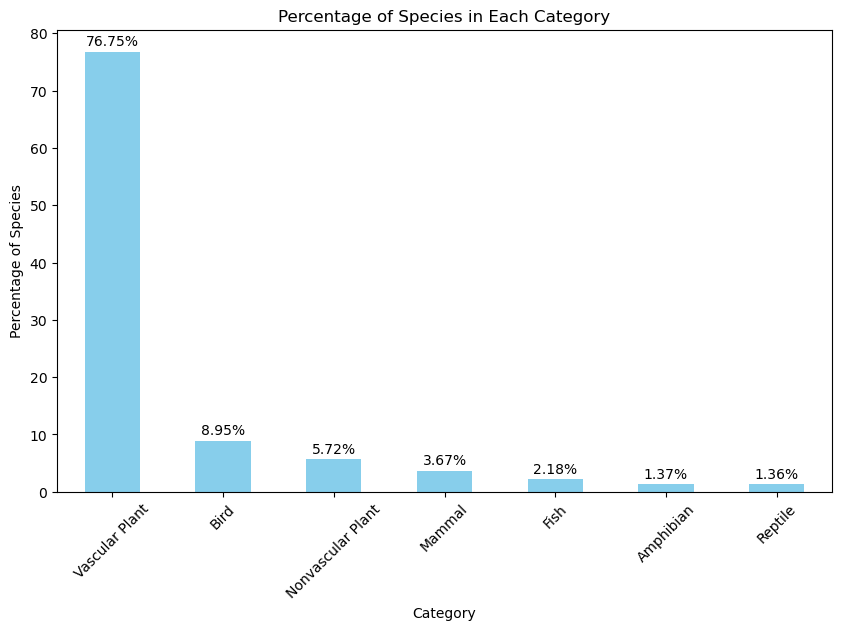

In [145]:
# vislualize the percentage of species in each category
plt.figure(figsize=(10, 6))

category_percentages.plot(kind='bar', color='skyblue')

plt.title('Percentage of Species in Each Category')

# give a label to each percentage bar
for index, value in enumerate(category_percentages):
    plt.text(index, value + 0.5, f'{value:.2f}%', ha='center', va='bottom')
plt.xlabel('Category')
plt.ylabel('Percentage of Species')
plt.xticks(rotation=45)
plt.show()

In [146]:
# explore conservation status counts
species_info_df['conservation_status'].value_counts()

conservation_status
Species of Concern    161
Endangered             16
Threatened             10
In Recovery             4
Name: count, dtype: int64

In [147]:
# show as a percentage 
np.round(species_info_df['conservation_status'].value_counts(normalize=True) * 100,2)

conservation_status
Species of Concern    84.29
Endangered             8.38
Threatened             5.24
In Recovery            2.09
Name: proportion, dtype: float64

C:\Users\aidan\AppData\Local\Temp\ipykernel_6152\3707994244.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=status_counts.values, y=status_counts.index, palette='viridis')


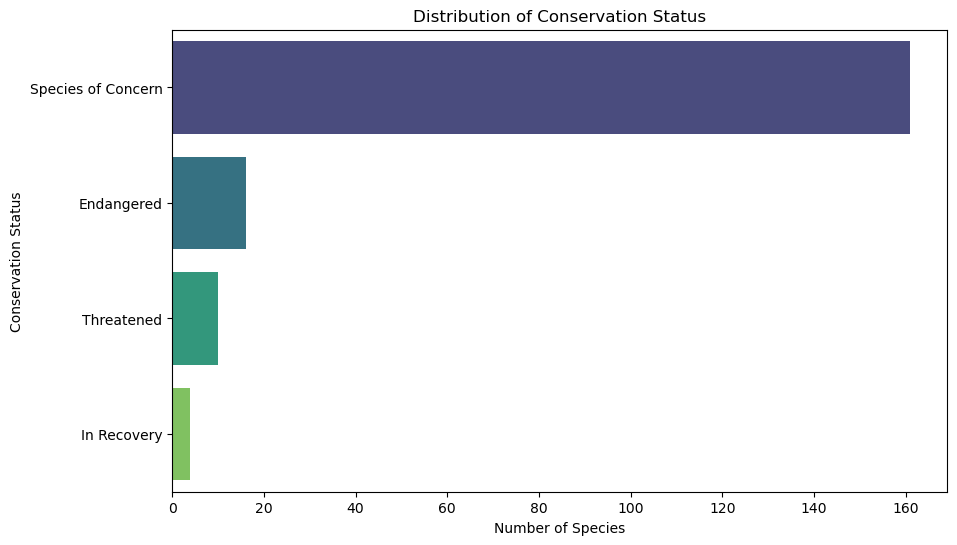

In [148]:
# visualise conservation status counts

status_counts = species_info_df['conservation_status'].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(x=status_counts.values, y=status_counts.index, palette='viridis')


plt.title('Distribution of Conservation Status')
plt.xlabel('Number of Species')
plt.ylabel('Conservation Status')
plt.show()



In [149]:
# we now want to look at how conservation status varies across species

conservation_by_category = pd.crosstab(species_info_df['category'], species_info_df['conservation_status'])

conservation_by_category

conservation_status,Endangered,In Recovery,Species of Concern,Threatened
category,,,,
Amphibian,1,0,4,2
Bird,4,3,72,0
Fish,3,0,4,4
Mammal,7,1,28,2
Nonvascular Plant,0,0,5,0
Reptile,0,0,5,0
Vascular Plant,1,0,43,2


In [150]:
conservation_percentages = (
    pd.crosstab(
        species_info_df['category'],
        species_info_df['conservation_status'],
        normalize='index'
    ) * 100
).round(2)

conservation_percentages

conservation_status,Endangered,In Recovery,Species of Concern,Threatened
category,,,,
Amphibian,14.29,0.00,57.14,28.57
Bird,5.06,3.80,91.14,0.00
Fish,27.27,0.00,36.36,36.36
Mammal,18.42,2.63,73.68,5.26
Nonvascular Plant,0.00,0.00,100.00,0.00
Reptile,0.00,0.00,100.00,0.00
Vascular Plant,2.17,0.00,93.48,4.35


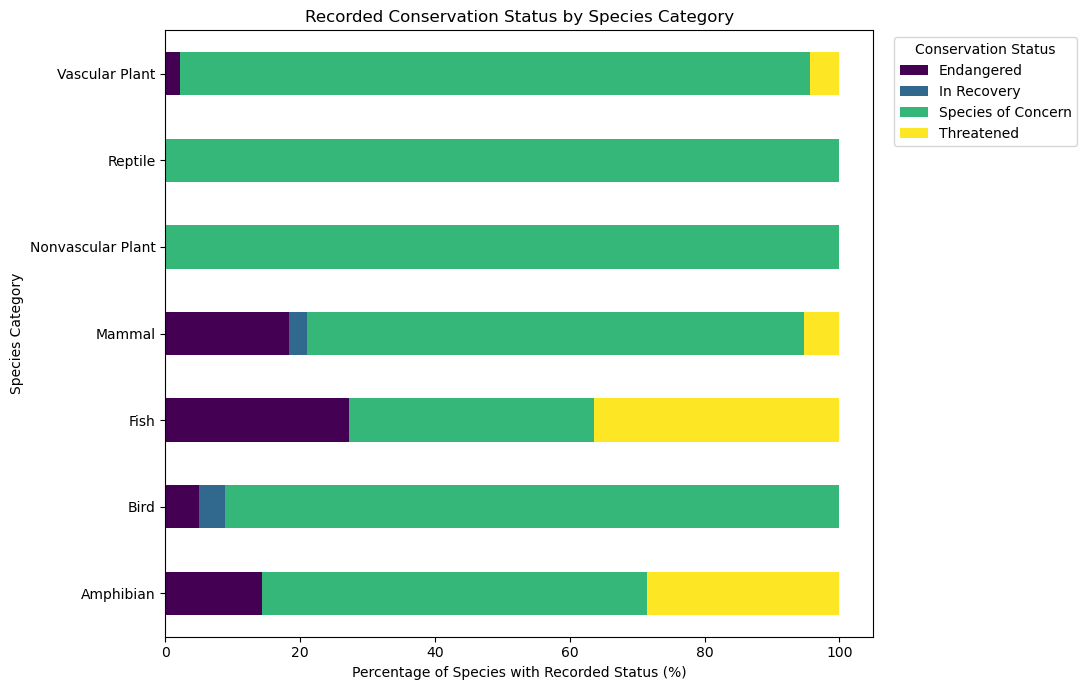

In [151]:
# visualise using a stacked bar chart 
conservation_percentages.plot(
    kind='barh',
    stacked=True,
    figsize=(11, 7),
    colormap='viridis'
)

plt.title('Recorded Conservation Status by Species Category')
plt.xlabel('Percentage of Species with Recorded Status (%)')
plt.ylabel('Species Category')
plt.legend(
    title='Conservation Status',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

In [152]:
# we now want to explore observations by park

park_observations = (
    observations_df.groupby('park_name')['observations']
    .sum()
    .sort_values(ascending=False)
)

park_observations

park_name
Yellowstone National Park              1442314
Yosemite National Park                  862836
Bryce National Park                     575901
Great Smoky Mountains National Park     431378
Name: observations, dtype: int64

In [153]:
# show this as a percentage 
park_percentages = (
    park_observations / park_observations.sum() * 100
).round(2)

park_percentages

park_name
Yellowstone National Park              43.54
Yosemite National Park                 26.05
Bryce National Park                    17.39
Great Smoky Mountains National Park    13.02
Name: observations, dtype: float64

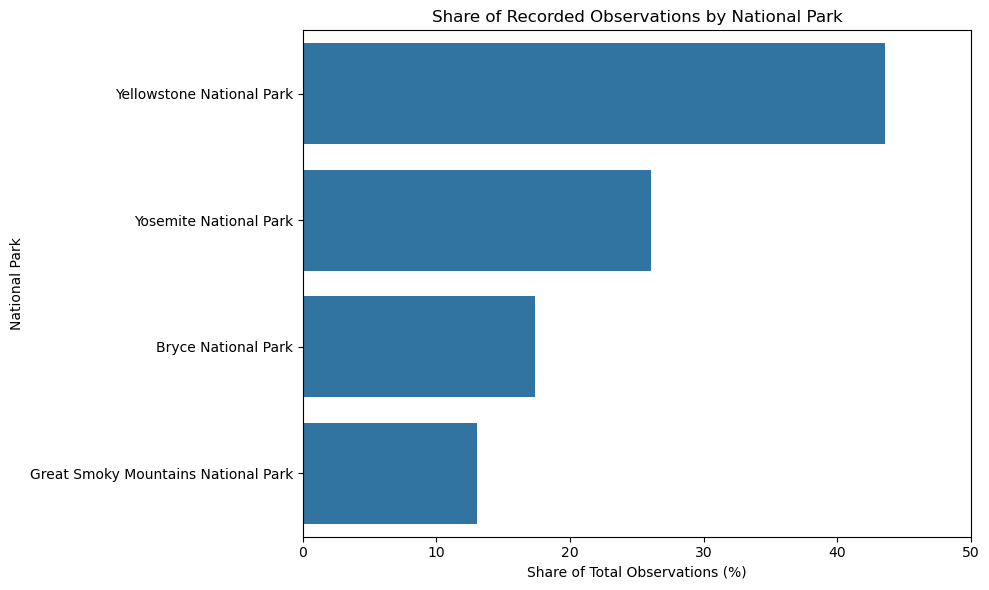

In [154]:
# visualise the results
plt.figure(figsize=(10, 6))

sns.barplot(
    x=park_percentages.values,
    y=park_percentages.index
)

plt.title('Share of Recorded Observations by National Park')
plt.xlabel('Share of Total Observations (%)')
plt.ylabel('National Park')
plt.xlim(0, 50)

plt.tight_layout()
plt.show()

In [ ]:
# get unique scientific name vales to compare with length of dataset 
species_info_df['scientific_name'].nunique()

5541

In [156]:
len(species_info_df)

5824